# Praktikum 1 - Klasifikasi Cat vs. Dog dengan CNN

**Nama:** Agus
**NIM:** 244107020049

[Sumber modul](https://polinema.gitbook.io/jti-modul-praktikum-pembelajaran-mesin-2025-2026/js14-convolutional-neural-network/praktikum-1)

Dataset adalah lampiran modul dari Google Drive: 8.000 citra latih dan 2.000 citra uji (kucing/anjing), ditambah 2 citra `single_prediction`.
Arsip `data/catdog.zip` berukuran 233 MB sehingga tidak dimasukkan ke Git. Sel pertama mengunduh dan mengekstraknya jika belum ada
(URL dan SHA-256 tercatat di `data/provenance.json`).

Langkah, arsitektur, dan hyperparameter mengikuti modul. Penyesuaian yang diperlukan:
* `keras.preprocessing.image.ImageDataGenerator` **sudah tidak ada di Keras 3** (`ImportError`). Penggantinya API Keras 3 dengan parameter yang sama:
  `image_dataset_from_directory` (64×64, batch 32, label biner) dan layer augmentasi `Rescaling(1/255)`, `RandomShear(0.2)`,
  `RandomZoom(0.2)`, serta `RandomFlip('horizontal')`. Augmentasi hanya diterapkan pada data training, sama seperti modul.
* Prediksi satu citra memakai threshold `> 0.5`. Kode modul `result[0][0] == 1` membandingkan probabilitas sigmoid (float) dengan 1,
  sehingga hampir selalu menghasilkan `cat`. Citra uji juga dibagi 255 agar skalanya sama dengan data latih.

In [1]:
import sys
import numpy as np
import tensorflow as tf
tf.keras.utils.set_random_seed(42)
print("Kernel:", sys.executable)
print("TensorFlow:", tf.__version__)

Kernel: /Users/jergal/College/machine-learning-smt-5/.venv/bin/python
TensorFlow: 2.21.0


In [2]:
# Unduh dan ekstrak dataset modul bila belum tersedia.
import hashlib, urllib.request, zipfile
from pathlib import Path
ZIP = Path('data/catdog.zip')
URL = 'https://drive.usercontent.google.com/download?id=1vYrqBI1VmiXXJd5sgtKK2nuQvC8T1ryb&export=download&confirm=t'
if not Path('dataset/training_set').exists():
    if not Path('data/dataset/training_set').exists():
        if not ZIP.exists():
            urllib.request.urlretrieve(URL, ZIP)
        assert hashlib.sha256(ZIP.read_bytes()).hexdigest() == '866b75276dd83d3c2a64811c44b1f74ed2bee200ed03d930d89738661997e933'
        with zipfile.ZipFile(ZIP) as z:
            members = [m for m in z.namelist() if m.startswith('dataset/') and not m.endswith('.DS_Store')]
            assert all('..' not in Path(m).parts for m in members)
            z.extractall('data', members)
import os
os.chdir('data')   # agar path 'dataset/...' sama persis dengan modul
for split in ['training_set', 'test_set']:
    print(split, {c: len(list(Path('dataset', split, c).glob('*.jpg'))) for c in ['cats', 'dogs']})

training_set {'cats': 4000, 'dogs': 4000}
test_set {'cats': 1000, 'dogs': 1000}


## Langkah 1 - Import Library

In [3]:
import tensorflow as tf
from tensorflow.keras import layers
# Modul: from keras.preprocessing.image import ImageDataGenerator  (dihapus di Keras 3)

## Langkah 2 - Pra Pengolahan Data

Manipulasi citra yang dilakukan: normalisasi nilai piksel, koreksi kemiringan (shear), pembesaran (zoom), dan flip.

### Langkah 2.1 - Pra Pengolahan Data Training

In [4]:
train_augment = tf.keras.Sequential([
    layers.Rescaling(1./255),
    layers.RandomShear(x_factor=0.2, y_factor=0.2),
    layers.RandomZoom(0.2),
    layers.RandomFlip('horizontal'),
])
training_set = tf.keras.utils.image_dataset_from_directory('dataset/training_set',
                                                           image_size = (64, 64),
                                                           batch_size = 32,
                                                           label_mode = 'binary',
                                                           seed = 42)
class_indices = {name: i for i, name in enumerate(training_set.class_names)}
training_set = training_set.map(lambda x, y: (train_augment(x, training=True), y)).prefetch(tf.data.AUTOTUNE)

Found 8000 files belonging to 2 classes.


### Langkah 2.2 - Pra Pengolahan Data Testing

In [5]:
test_rescale = layers.Rescaling(1./255)
test_set = tf.keras.utils.image_dataset_from_directory('dataset/test_set',
                                                       image_size = (64, 64),
                                                       batch_size = 32,
                                                       label_mode = 'binary',
                                                       shuffle = False)
test_set = test_set.map(lambda x, y: (test_rescale(x), y)).prefetch(tf.data.AUTOTUNE)

Found 2000 files belonging to 2 classes.


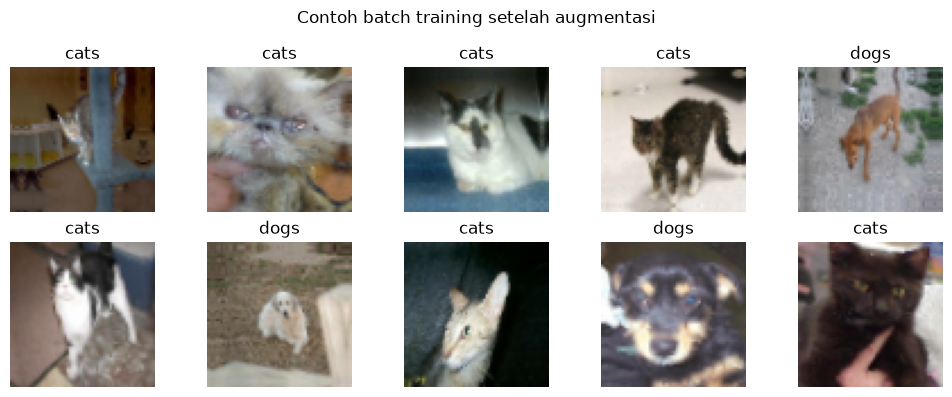

In [6]:
import matplotlib.pyplot as plt
xb, yb = next(iter(training_set))
plt.figure(figsize=(10, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1); plt.imshow(xb[i].numpy().clip(0, 1)); plt.axis('off')
    plt.title(list(class_indices)[int(yb[i][0])])
plt.suptitle('Contoh batch training setelah augmentasi'); plt.tight_layout(); plt.show()

## Langkah 3 - Pembuatan Model CNN

### Langkah 3.1 - Inisiasi Model CNN

In [7]:
cnn = tf.keras.models.Sequential()

### Langkah 3.2 - Pembuatan Layer Konvolusi 1

In [8]:
cnn.add(tf.keras.layers.Input(shape=[64, 64, 3]))
cnn.add(tf.keras.layers.Conv2D(filters=32, kernel_size=3, activation='relu'))

### Langkah 3.3 - Pembuatan Layer Pooling 1

In [9]:
cnn.add(tf.keras.layers.MaxPool2D(pool_size=2, strides=2))

### Langkah 3.4 - Pembuatan Layer Konvolusi 2 dan Pooling 2

In [10]:
cnn.add(tf.keras.layers.Conv2D(filters=32, kernel_size=3, activation='relu'))
cnn.add(tf.keras.layers.MaxPool2D(pool_size=2, strides=2))

### Langkah 3.5 - Flattening

In [11]:
cnn.add(tf.keras.layers.Flatten())

### Langkah 3.6 - Fully Connected Layer 1 (Input)

In [12]:
cnn.add(tf.keras.layers.Dense(units=128, activation='relu'))

### Langkah 3.7 - Fully Connected Layer 2 (Output)

In [13]:
cnn.add(tf.keras.layers.Dense(units=1, activation='sigmoid'))

### Langkah 3.8 - Compile Model CNN

Loss *binary crossentropy* dipakai karena hanya ada dua kelas, yaitu kucing dan anjing.

In [14]:
cnn.compile(optimizer = 'adam', loss = 'binary_crossentropy', metrics = ['accuracy'])
cnn.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 62, 62, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 29, 29, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       802,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 813,217 (3.10 MB)

 Trainable params: 813,217 (3.10 MB)

 Non-trainable params: 0 (0.00 B)

## Langkah 4 - Fit CNN

In [15]:
import time
t0 = time.perf_counter()
history = cnn.fit(x = training_set, validation_data = test_set, epochs = 25, verbose = 2)
print(f'Waktu latih: {time.perf_counter() - t0:.1f} detik')

Epoch 1/25


/Users/jergal/College/machine-learning-smt-5/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


250/250 - 5s - 19ms/step - accuracy: 0.5906 - loss: 0.6654 - val_accuracy: 0.6625 - val_loss: 0.6169


Epoch 2/25


250/250 - 5s - 18ms/step - accuracy: 0.6606 - loss: 0.6187 - val_accuracy: 0.7065 - val_loss: 0.5839


Epoch 3/25


... (42 outputs left out)

250/250 - 6s - 23ms/step - accuracy: 0.8255 - loss: 0.3920 - val_accuracy: 0.8140 - val_loss: 0.4087


Epoch 25/25


250/250 - 6s - 22ms/step - accuracy: 0.8158 - loss: 0.3956 - val_accuracy: 0.8140 - val_loss: 0.4265


Waktu latih: 129.8 detik


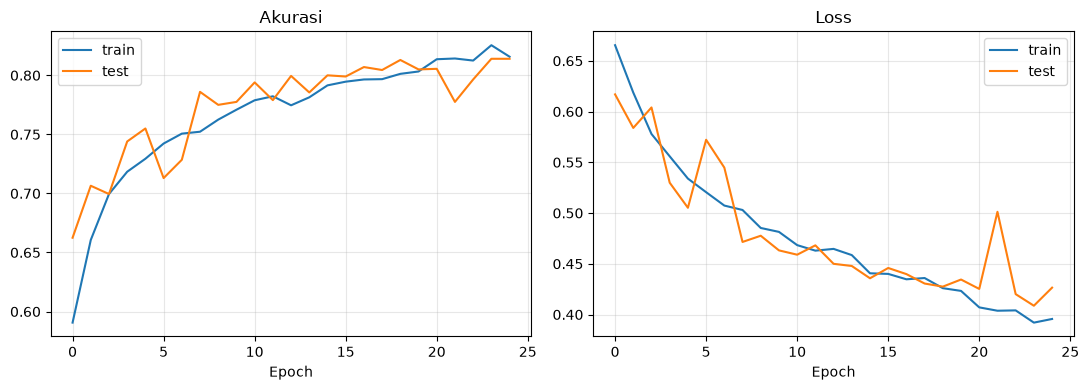

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(history.history['accuracy'], label='train'); ax[0].plot(history.history['val_accuracy'], label='test')
ax[1].plot(history.history['loss'], label='train'); ax[1].plot(history.history['val_loss'], label='test')
ax[0].set_title('Akurasi'); ax[1].set_title('Loss')
for a in ax: a.set_xlabel('Epoch'); a.legend(); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

## Langkah 5 - Prediksi dengan 1 Citra

{'cats': 0, 'dogs': 1}


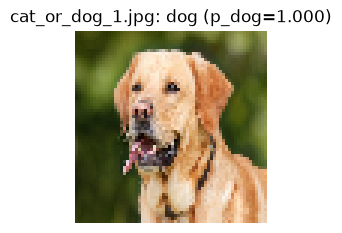

{'cats': 0, 'dogs': 1}


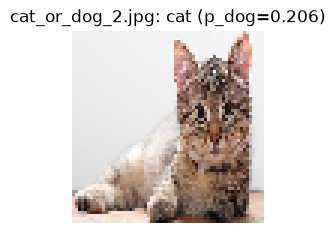

In [17]:
import numpy as np
from keras.preprocessing import image
for fname in ['cat_or_dog_1.jpg', 'cat_or_dog_2.jpg']:
    test_image = image.load_img('dataset/single_prediction/' + fname, target_size = (64, 64))
    shown = test_image
    test_image = image.img_to_array(test_image) / 255.0
    test_image = np.expand_dims(test_image, axis = 0)
    result = cnn.predict(test_image, verbose = 0)
    print(class_indices)
    if result[0][0] > 0.5:
        prediction = 'dog'
    else:
        prediction = 'cat'
    plt.figure(figsize=(2.5, 2.5)); plt.imshow(shown); plt.axis('off')
    plt.title(f'{fname}: {prediction} (p_dog={result[0][0]:.3f})'); plt.show()

## Evaluasi pada data uji

              precision    recall  f1-score   support

        cats     0.8420    0.7730    0.8060      1000
        dogs     0.7902    0.8550    0.8213      1000

    accuracy                         0.8140      2000
   macro avg     0.8161    0.8140    0.8137      2000
weighted avg     0.8161    0.8140    0.8137      2000



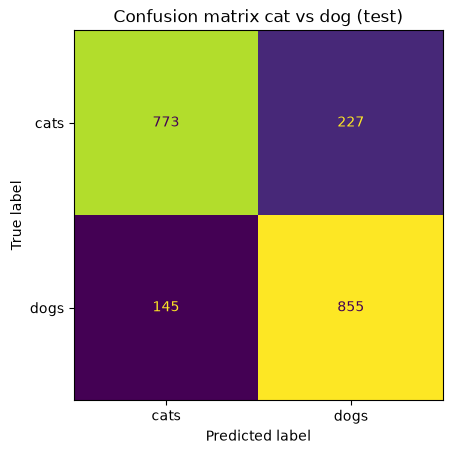

Akurasi test terbaik: 0.8140 pada epoch 24; epoch 25: 0.8140


In [18]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
y_true = np.concatenate([yb.numpy().ravel() for _, yb in test_set]).astype(int)
prob = cnn.predict(test_set, verbose=0).ravel()
y_pred = (prob > 0.5).astype(int)
print(classification_report(y_true, y_pred, target_names=list(class_indices), digits=4))
ConfusionMatrixDisplay.from_predictions(y_true, y_pred, display_labels=list(class_indices), colorbar=False)
plt.title('Confusion matrix cat vs dog (test)'); plt.show()
best = int(np.argmax(history.history['val_accuracy']))
print(f"Akurasi test terbaik: {history.history['val_accuracy'][best]:.4f} pada epoch {best + 1}; epoch 25: {history.history['val_accuracy'][-1]:.4f}")

## Analisis

**Hasil:** akurasi test akhir (epoch 25) **81,40%**. Precision/recall: cats 0,842/0,773 dan dogs 0,790/0,855, sehingga model sedikit lebih condong menebak "dog". Pelatihan 25 epoch membutuhkan 130 detik di CPU Apple M4.

* **Kurva belajar.** Akurasi train naik dari 59% ke 82%, sementara akurasi test mengikuti di kisaran 66-81%. Celah train-test kecil (≤ 2 poin pada epoch terakhir) karena augmentasi shear/zoom/flip menghasilkan variasi baru di setiap epoch. Augmentasi berfungsi sebagai regularisasi (Shorten & Khoshgoftaar, 2019). Akurasi test berfluktuasi (misalnya turun ke 77,8% pada epoch 22), sehingga pemilihan epoch sebaiknya memakai data validasi terpisah, bukan data test.
* **Prediksi satu citra.** `cat_or_dog_1.jpg` (anjing) diprediksi **dog** dengan p = 1,000, dan `cat_or_dog_2.jpg` (kucing) diprediksi **cat** dengan p_dog = 0,206. Dengan kode modul `result[0][0] == 1`, citra kedua tetap benar karena 0,206 ≠ 1. Citra pertama hanya benar jika sigmoid jenuh tepat bernilai 1,0. Probabilitas seperti 0,9 akan salah dilabeli "cat", sehingga threshold 0,5 adalah aturan keputusan yang benar.
* **Perbandingan literatur.** Elson dkk. (2007) memperkirakan tebakan acak pada CAPTCHA Asirra (kucing vs anjing) hanya benar 50%, dan CAPTCHA ini dirancang dengan asumsi komputer sulit membedakan keduanya. Golle (2008) kemudian mencapai 82,7% dengan fitur warna dan tekstur + SVM. CNN 2 lapis yang kecil ini (64×64 piksel, 8.000 citra) mencapai 81,4% tanpa rekayasa fitur manual. Parkhi dkk. (2012) memakai model bentuk dan tekstur yang jauh lebih kompleks untuk klasifikasi ras. Akurasi > 95% umumnya membutuhkan CNN yang lebih dalam atau *transfer learning* dari ImageNet.

## Rujukan

1. LeCun, Y., Bottou, L., Bengio, Y., & Haffner, P. (1998). Gradient-based learning applied to document recognition. *Proceedings of the IEEE*, 86(11), 2278-2324. https://doi.org/10.1109/5.726791
2. Elson, J., Douceur, J. R., Howell, J., & Saul, J. (2007). Asirra: A CAPTCHA that exploits interest-aligned manual image categorization. *Proceedings of the 14th ACM Conference on Computer and Communications Security (CCS)*, 366-374. https://doi.org/10.1145/1315245.1315291
3. Parkhi, O. M., Vedaldi, A., Zisserman, A., & Jawahar, C. V. (2012). Cats and dogs. *IEEE Conference on Computer Vision and Pattern Recognition (CVPR)*, 3498-3505. https://doi.org/10.1109/CVPR.2012.6248092
4. Shorten, C., & Khoshgoftaar, T. M. (2019). A survey on image data augmentation for deep learning. *Journal of Big Data*, 6, 60. https://doi.org/10.1186/s40537-019-0197-0
5. Golle, P. (2008). Machine learning attacks against the Asirra CAPTCHA. *Proceedings of the 15th ACM Conference on Computer and Communications Security (CCS)*, 535-542. https://doi.org/10.1145/1455770.1455838